# Task 2 - Exploratory Data Analysis (EDA)

## Objective
To perform exploratory data analysis on the cleaned employee dataset.

## Dataset
clean_data.csv

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [4]:
df = pd.read_csv("data/clean_data.csv")

print("Dataset Loaded Successfully!")
print(df.head())
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
   Employee_ID        Name   Age   Salary Department   Join_Date        City  \
0            1  Employee_1  38.0  25500.0         Hr  2024-01-02     Madurai   
1            2  Employee_2  38.0  26000.0    Finance  2024-01-03  Coimbatore   
2            3  Employee_3  38.0  26500.0      Sales  2024-01-04      Trichy   
3            4  Employee_4  38.0  27000.0         It  2024-01-05     Chennai   
4            5  Employee_5  38.0  27500.0         Hr  2024-01-06     Madurai   

   Join_Date_Missing  Salary_Outlier  
0              False           False  
1              False           False  
2              False           False  
3              False           False  
4              False           False  
Dataset Shape: (100, 9)


## 1. Summary Statistics

Calculate mean, median, minimum, maximum and standard deviation for Age and Salary.

In [ ]:

summary_stats = df[["Age", "Salary"]].agg(
    ["mean", "median", "min", "max", "std"]
)

print("SUMMARY STATISTICS")
print(summary_stats)

SUMMARY STATISTICS
              Age        Salary
mean    37.800000  52605.000000
median  38.000000  52000.000000
min     20.000000  25500.000000
max     54.000000  93500.000000
std      8.987084  13887.952595


## 2. GroupBy and Aggregation

Compare employee count, average age and average salary across departments.


In [ ]:
department_analysis = df.groupby("Department").agg(
    Employee_Count=("Employee_ID", "count"),
    Average_Age=("Age", "mean"),
    Average_Salary=("Salary", "mean"),
    Minimum_Salary=("Salary", "min"),
    Maximum_Salary=("Salary", "max")
)

print("DEPARTMENT-WISE ANALYSIS")
print(department_analysis.round(2))

DEPARTMENT-WISE ANALYSIS
            Employee_Count  Average_Age  Average_Salary  Minimum_Salary  \
Department                                                                
Finance                 22        36.73        53363.64         26000.0   
Hr                      32        39.97        48171.88         25500.0   
It                      23        37.26        54608.70         27000.0   
Sales                   23        36.35        56043.48         26500.0   

            Maximum_Salary  
Department                  
Finance            74000.0  
Hr                 73500.0  
It                 75000.0  
Sales              93500.0  


In [7]:
city_analysis = df.groupby("City").agg(
    Employee_Count=("Employee_ID", "count"),
    Average_Salary=("Salary", "mean"),
    Average_Age=("Age", "mean")
)

print("CITY-WISE ANALYSIS")
print(city_analysis.round(2))

CITY-WISE ANALYSIS
            Employee_Count  Average_Salary  Average_Age
City                                                   
Chennai                 22        54681.82        38.68
Coimbatore              23        52260.87        37.78
Madurai                 33        49060.61        37.24
Trichy                  22        56204.55        37.77


## 3. Correlation Analysis

Find correlations between numeric columns and identify the top 3 relationships.

In [8]:
numeric_df = df[["Employee_ID", "Age", "Salary"]]
correlation_matrix = numeric_df.corr()

print("CORRELATION MATRIX")
print(correlation_matrix)
correlation_pairs = correlation_matrix.unstack()
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) <
    correlation_pairs.index.get_level_values(1)
]
top_3 = correlation_pairs.reindex(
    correlation_pairs.abs().sort_values(ascending=False).index
).head(3)

print("\nTOP 3 CORRELATION RELATIONSHIPS")
print(top_3)

CORRELATION MATRIX
             Employee_ID       Age    Salary
Employee_ID     1.000000  0.035448  0.875079
Age             0.035448  1.000000 -0.008409
Salary          0.875079 -0.008409  1.000000

TOP 3 CORRELATION RELATIONSHIPS
Employee_ID  Salary         0.875079
Age          Employee_ID    0.035448
             Salary        -0.008409
dtype: float64


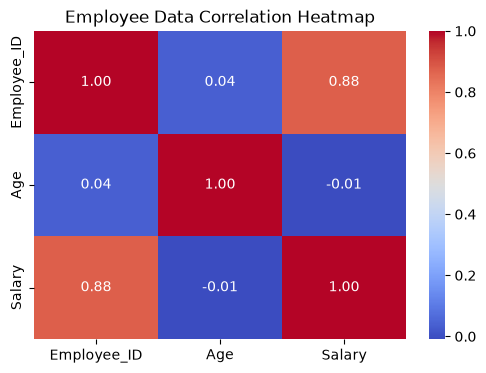

In [9]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Employee Data Correlation Heatmap")
plt.show()

## 4. Business Questions and Answers

### Question 1
Which department has the highest average salary?

### Question 2
Which city has the highest number of employees?

### Question 3
What is the average salary of all employees?

### Question 4
Which department has the highest number of employees?

### Question 5
How many employees have salary outliers?

In [10]:
dept_salary = df.groupby("Department")["Salary"].mean()

print("Q1: Department with highest average salary")
print(dept_salary.idxmax())
print("Average Salary:", round(dept_salary.max(), 2))

city_count = df.groupby("City")["Employee_ID"].count()

print("\nQ2: City with highest number of employees")
print(city_count.idxmax())
print("Employee Count:", city_count.max())


print("\nQ3: Average salary of all employees")
print("Average Salary:", round(df["Salary"].mean(), 2))


dept_count = df.groupby("Department")["Employee_ID"].count()

print("\nQ4: Department with highest number of employees")
print(dept_count.idxmax())
print("Employee Count:", dept_count.max())


outlier_count = df["Salary_Outlier"].sum()

print("\nQ5: Employees with salary outliers")
print("Outlier Count:", outlier_count)

Q1: Department with highest average salary
Sales
Average Salary: 56043.48

Q2: City with highest number of employees
Madurai
Employee Count: 33

Q3: Average salary of all employees
Average Salary: 52605.0

Q4: Department with highest number of employees
Hr
Employee Count: 32

Q5: Employees with salary outliers
Outlier Count: 1


## 5. Merge Department Budget Table

Create a department budget table and merge it with the employee dataset using pd.merge().

In [11]:
budget_data = {
    "Department": ["Hr", "Finance", "Sales", "It"],
    "Department_Budget": [200000, 300000, 250000, 400000]
}

budget_df = pd.DataFrame(budget_data)

print("DEPARTMENT BUDGET TABLE")
print(budget_df)

DEPARTMENT BUDGET TABLE
  Department  Department_Budget
0         Hr             200000
1    Finance             300000
2      Sales             250000
3         It             400000


In [12]:
merged_df = pd.merge(
    df,
    budget_df,
    on="Department",
    how="left"
)

print("MERGED DATASET")
print(merged_df.head())

print("\nDepartment-wise Budget")
print(
    merged_df.groupby("Department")["Department_Budget"].first()
)

MERGED DATASET
   Employee_ID        Name   Age   Salary Department   Join_Date        City  \
0            1  Employee_1  38.0  25500.0         Hr  2024-01-02     Madurai   
1            2  Employee_2  38.0  26000.0    Finance  2024-01-03  Coimbatore   
2            3  Employee_3  38.0  26500.0      Sales  2024-01-04      Trichy   
3            4  Employee_4  38.0  27000.0         It  2024-01-05     Chennai   
4            5  Employee_5  38.0  27500.0         Hr  2024-01-06     Madurai   

   Join_Date_Missing  Salary_Outlier  Department_Budget  
0              False           False             200000  
1              False           False             300000  
2              False           False             250000  
3              False           False             400000  
4              False           False             200000  

Department-wise Budget
Department
Finance    300000
Hr         200000
It         400000
Sales      250000
Name: Department_Budget, dtype: int64


## 6. Bonus Challenge - Pivot Table

Create a pivot table using Department and City.

In [13]:
pivot_table = pd.pivot_table(
    df,
    values="Employee_ID",
    index="Department",
    columns="City",
    aggfunc="count",
    fill_value=0
)

print("DEPARTMENT AND CITY PIVOT TABLE")
print(pivot_table)

DEPARTMENT AND CITY PIVOT TABLE
City        Chennai  Coimbatore  Madurai  Trichy
Department                                      
Finance           0          20        2       0
Hr                2           3       25       2
It               20           0        3       0
Sales             0           0        3      20
